### Lab 03 – Developing a Tiny Transformer Language Model

**Module:** PUSL 3205 – Large Language Models and Generative AI

#### Setup – Install required packages
Run this cell once if the packages are not already installed.



In [1]:
%pip install -q datasets torch matplotlib pandas numpy


In [1]:
import os, json, math, random, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from datasets import load_dataset

# ------------------------------------------------------------
# STEP 1: IMPORTS, REPRODUCIBILITY AND DEVICE
# ------------------------------------------------------------
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU unavailable; using CPU.")


PyTorch: 2.14.1+cu130
Device: cuda
GPU: Tesla T4


In [2]:
# ------------------------------------------------------------
# STEP 2: LOAD TINYSTORIES DATASET
# ------------------------------------------------------------
DATASET_NAME = "roneneldan/TinyStories"
NUMBER_OF_STORIES = 1500

dataset = load_dataset(DATASET_NAME, split=f"train[:{NUMBER_OF_STORIES}]")
stories = [row["text"].strip() for row in dataset if row.get("text", "").strip()]

if len(stories) < 10:
    raise ValueError("Not enough stories were loaded. Check the dataset download.")

print("\\nDataset loaded:", len(stories), "usable stories")
for i, story in enumerate(stories[:3], start=1):
    print(f"\\nSTORY {i}\\n{story[:800]}\\n" + "-" * 60)

README.md:   0%|          | 0.00/1.06k [00:00<?, ?B/s]

data/train-00000-of-00004-2d5a1467fff108(…): reconstructing file:   0%|          |  0.00B /  249MB            

data/train-00000-of-00004-2d5a1467fff108(…): downloading bytes:           |  0.00B            

data/train-00001-of-00004-5852b56a2bd28f(…): reconstructing file:   0%|          |  0.00B /  248MB            

data/train-00001-of-00004-5852b56a2bd28f(…): downloading bytes:           |  0.00B            

data/train-00002-of-00004-a26307300439e9(…): reconstructing file:   0%|          |  0.00B /  246MB            

... (4 outputs left out)

data/validation-00000-of-00001-869c898b5(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/2119719 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/21990 [00:00<?, ? examples/s]

\nDataset loaded: 1500 usable stories
\nSTORY 1\nOne day, a little girl named Lily found a needle in her room. She knew it was difficult to play with it because it was sharp. Lily wanted to share the needle with her mom, so she could sew a button on her shirt.

Lily went to her mom and said, "Mom, I found this needle. Can you share it with me and sew my shirt?" Her mom smiled and said, "Yes, Lily, we can share the needle and fix your shirt."

Together, they shared the needle and sewed the button on Lily's shirt. It was not difficult for them because they were sharing and helping each other. After they finished, Lily thanked her mom for sharing the needle and fixing her shirt. They both felt happy because they had shared and worked together.\n------------------------------------------------------------
\nSTORY 2\nOnce upon a time, there was a little car named Beep. Beep loved to go fast and play in the sun. Beep was a healthy car because he always had good fuel. Good fuel made Beep happ

\nAverage words: 169.52
Shortest story: 61
Longest story: 837


,story,word_count,character_count
0,"One day, a little girl named Lily found a need...",134,701
1,"Once upon a time, there was a little car named...",142,705
2,"One day, a little fish named Fin was swimming ...",168,822
3,"Once upon a time, in a land full of trees, the...",163,845
4,"Once upon a time, there was a little girl name...",129,638


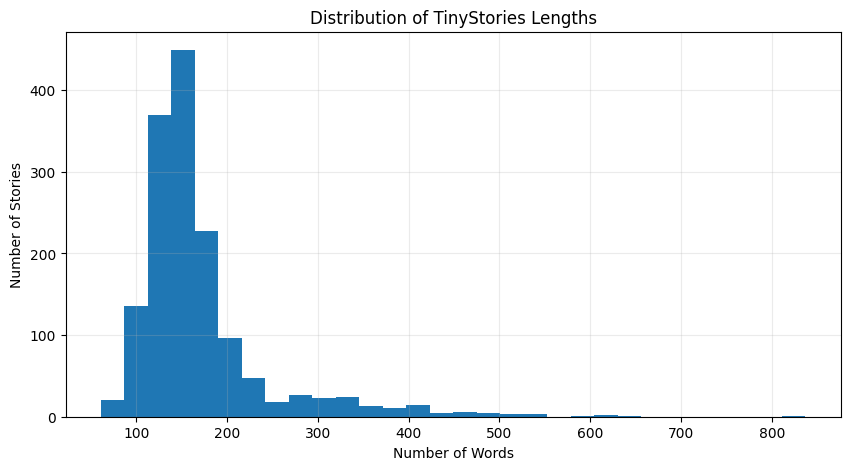

In [3]:
# ------------------------------------------------------------
# STEP 3: DATASET EXPLORATION
# ------------------------------------------------------------
story_lengths = [len(story.split()) for story in stories]
story_df = pd.DataFrame({
    "story": stories,
    "word_count": story_lengths,
    "character_count": [len(story) for story in stories]
})

print("\\nAverage words:", round(story_df["word_count"].mean(), 2))
print("Shortest story:", int(story_df["word_count"].min()))
print("Longest story:", int(story_df["word_count"].max()))
display(story_df.head())

plt.figure(figsize=(10, 5))
plt.hist(story_lengths, bins=30)
plt.title("Distribution of TinyStories Lengths")
plt.xlabel("Number of Words")
plt.ylabel("Number of Stories")
plt.grid(alpha=0.25)
plt.show()

In [4]:
# ------------------------------------------------------------
# STEP 4: CHARACTER-LEVEL TOKENIZATION
# ------------------------------------------------------------
text_data = "\\n".join(stories)
vocab = sorted(set(text_data))
vocab_size = len(vocab)

stoi = {ch: i for i, ch in enumerate(vocab)}
itos = {i: ch for i, ch in enumerate(vocab)}

def encode(text):
    unknown = sorted(set(ch for ch in text if ch not in stoi))
    if unknown:
        raise ValueError(f"Characters not in vocabulary: {unknown}")
    return [stoi[ch] for ch in text]

def decode(token_ids):
    return "".join(itos[int(token)] for token in token_ids)

encoded_text = torch.tensor(encode(text_data), dtype=torch.long)
print("\\nVocabulary size:", vocab_size)
print("Total characters:", len(encoded_text))
print("Encoded sample:", encoded_text[:40].tolist())
print("Decoded sample:", decode(encoded_text[:200]))

\nVocabulary size: 78
Total characters: 1303952
Encoded sample: [32, 58, 49, 1, 48, 45, 69, 6, 1, 45, 1, 56, 53, 64, 64, 56, 49, 1, 51, 53, 62, 56, 1, 58, 45, 57, 49, 48, 1, 29, 53, 56, 69, 1, 50, 59, 65, 58, 48, 1]
Decoded sample: One day, a little girl named Lily found a needle in her room. She knew it was difficult to play with it because it was sharp. Lily wanted to share the needle with her mom, so she could sew a button on


In [5]:
# ------------------------------------------------------------
# STEP 5: PREPARE NEXT-CHARACTER TRAINING DATA
# ------------------------------------------------------------
split_index = int(0.90 * len(encoded_text))
train_data = encoded_text[:split_index]
val_data = encoded_text[split_index:]

BATCH_SIZE = 32
BLOCK_SIZE = 128

if len(train_data) <= BLOCK_SIZE or len(val_data) <= BLOCK_SIZE:
    raise ValueError("Not enough text for the selected BLOCK_SIZE.")

def get_batch(split):
    source = train_data if split == "train" else val_data
    starts = torch.randint(0, len(source) - BLOCK_SIZE - 1, (BATCH_SIZE,))
    x = torch.stack([source[i:i + BLOCK_SIZE] for i in starts])
    y = torch.stack([source[i + 1:i + BLOCK_SIZE + 1] for i in starts])
    return x.to(device), y.to(device)

print("\\nTraining characters:", len(train_data))
print("Validation characters:", len(val_data))
sample_x, sample_y = get_batch("train")
print("Input batch shape:", tuple(sample_x.shape))
print("Target batch shape:", tuple(sample_y.shape))


\nTraining characters: 1173556
Validation characters: 130396
Input batch shape: (32, 128)
Target batch shape: (32, 128)


In [6]:
# ------------------------------------------------------------
# STEP 6: BUILD TRANSFORMER ARCHITECTURE
# ------------------------------------------------------------
EMBEDDING_SIZE = 128
NUM_HEADS = 4
NUM_LAYERS = 2
DROPOUT = 0.1

if EMBEDDING_SIZE % NUM_HEADS != 0:
    raise ValueError("EMBEDDING_SIZE must be divisible by NUM_HEADS.")

class Head(nn.Module):
    def __init__(self, head_size):
        super().__init__()
        self.key = nn.Linear(EMBEDDING_SIZE, head_size, bias=False)
        self.query = nn.Linear(EMBEDDING_SIZE, head_size, bias=False)
        self.value = nn.Linear(EMBEDDING_SIZE, head_size, bias=False)
        self.register_buffer("causal_mask", torch.tril(torch.ones(BLOCK_SIZE, BLOCK_SIZE)))
        self.dropout = nn.Dropout(DROPOUT)

    def forward(self, x):
        _, sequence_length, _ = x.shape
        key = self.key(x)
        query = self.query(x)
        value = self.value(x)
        scores = (query @ key.transpose(-2, -1)) * (key.shape[-1] ** -0.5)
        scores = scores.masked_fill(
            self.causal_mask[:sequence_length, :sequence_length] == 0,
            float("-inf")
        )
        weights = self.dropout(F.softmax(scores, dim=-1))
        return weights @ value

class MultiHeadAttention(nn.Module):
    def __init__(self, num_heads, head_size):
        super().__init__()
        self.heads = nn.ModuleList([Head(head_size) for _ in range(num_heads)])
        self.projection = nn.Linear(num_heads * head_size, EMBEDDING_SIZE)
        self.dropout = nn.Dropout(DROPOUT)

    def forward(self, x):
        combined = torch.cat([head(x) for head in self.heads], dim=-1)
        return self.dropout(self.projection(combined))

class FeedForward(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(EMBEDDING_SIZE, 4 * EMBEDDING_SIZE),
            nn.GELU(),
            nn.Linear(4 * EMBEDDING_SIZE, EMBEDDING_SIZE),
            nn.Dropout(DROPOUT)
        )

    def forward(self, x):
        return self.network(x)

class TransformerBlock(nn.Module):
    def __init__(self):
        super().__init__()
        head_size = EMBEDDING_SIZE // NUM_HEADS
        self.attention = MultiHeadAttention(NUM_HEADS, head_size)
        self.feed_forward = FeedForward()
        self.norm1 = nn.LayerNorm(EMBEDDING_SIZE)
        self.norm2 = nn.LayerNorm(EMBEDDING_SIZE)

    def forward(self, x):
        x = x + self.attention(self.norm1(x))
        x = x + self.feed_forward(self.norm2(x))
        return x

class TinyTransformer(nn.Module):
    def __init__(self):
        super().__init__()
        self.token_embedding = nn.Embedding(vocab_size, EMBEDDING_SIZE)
        self.position_embedding = nn.Embedding(BLOCK_SIZE, EMBEDDING_SIZE)
        self.blocks = nn.Sequential(*[TransformerBlock() for _ in range(NUM_LAYERS)])
        self.final_norm = nn.LayerNorm(EMBEDDING_SIZE)
        self.output_layer = nn.Linear(EMBEDDING_SIZE, vocab_size)
        self.apply(self._initialize_weights)

    def _initialize_weights(self, module):
        if isinstance(module, nn.Linear):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if module.bias is not None:
                nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def forward(self, index, targets=None):
        _, sequence_length = index.shape
        token_emb = self.token_embedding(index)
        positions = torch.arange(sequence_length, device=index.device)
        position_emb = self.position_embedding(positions)
        x = self.blocks(token_emb + position_emb)
        x = self.final_norm(x)
        logits = self.output_layer(x)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(
                logits.reshape(-1, vocab_size),
                targets.reshape(-1)
            )
        return logits, loss

    @torch.no_grad()
    def generate(self, index, max_new_tokens, temperature=0.8, top_k=40):
        self.eval()
        for _ in range(max_new_tokens):
            context = index[:, -BLOCK_SIZE:]
            logits, _ = self(context)
            logits = logits[:, -1, :] / max(temperature, 1e-5)
            if top_k is not None:
                k = min(top_k, logits.size(-1))
                values, _ = torch.topk(logits, k)
                logits = logits.masked_fill(logits < values[:, [-1]], float("-inf"))
            probabilities = F.softmax(logits, dim=-1)
            next_token = torch.multinomial(probabilities, num_samples=1)
            index = torch.cat((index, next_token), dim=1)
        return index

In [7]:
# ------------------------------------------------------------
# STEP 7: INITIALIZE MODEL, OPTIMIZER AND LOSS FUNCTION
# ------------------------------------------------------------
LEARNING_RATE = 0.001
WEIGHT_DECAY = 0.01
GRADIENT_CLIP = 1.0

model = TinyTransformer().to(device)
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)
loss_function = nn.CrossEntropyLoss()

total_parameters = sum(p.numel() for p in model.parameters())
print("\\nModel initialized successfully.")
print("Total parameters:", f"{total_parameters:,}")
print("Optimizer: AdamW | Loss: CrossEntropyLoss")
print("Learning rate:", LEARNING_RATE)

\nModel initialized successfully.
Total parameters: 432,462
Optimizer: AdamW | Loss: CrossEntropyLoss
Learning rate: 0.001


In [8]:
# ------------------------------------------------------------
# STEP 8: TRAIN TRANSFORMER
# ------------------------------------------------------------
EPOCHS = 10
STEPS_PER_EPOCH = 50       # Increase for longer training; CPU training takes longer.
VALIDATION_BATCHES = 20

train_losses = []
validation_losses = []

@torch.no_grad()
def estimate_loss(number_of_batches=VALIDATION_BATCHES):
    model.eval()
    metrics = {}
    for split in ("train", "val"):
        losses = []
        for _ in range(number_of_batches):
            x, y = get_batch(split)
            _, loss = model(x, y)
            losses.append(loss.item())
        metrics[split] = float(np.mean(losses))
    model.train()
    return metrics

start_time = time.time()
for epoch in range(EPOCHS):
    model.train()
    batch_losses = []

    for step in range(STEPS_PER_EPOCH):
        x, y = get_batch("train")
        optimizer.zero_grad(set_to_none=True)
        logits, loss = model(x, y)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), GRADIENT_CLIP)
        optimizer.step()
        batch_losses.append(loss.item())

    train_loss = float(np.mean(batch_losses))
    metrics = estimate_loss()
    train_losses.append(train_loss)
    validation_losses.append(metrics["val"])

    print(
        f"Epoch {epoch + 1:02d}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Validation Loss: {metrics['val']:.4f}"
    )

print(f"\\nTraining completed in {(time.time() - start_time) / 60:.2f} minutes.")


Epoch 01/10 | Train Loss: 2.7864 | Validation Loss: 2.3851
Epoch 02/10 | Train Loss: 2.3593 | Validation Loss: 2.3043
Epoch 03/10 | Train Loss: 2.3007 | Validation Loss: 2.2572
Epoch 04/10 | Train Loss: 2.2488 | Validation Loss: 2.1820
Epoch 05/10 | Train Loss: 2.1549 | Validation Loss: 2.0182
Epoch 06/10 | Train Loss: 2.0044 | Validation Loss: 1.8541
Epoch 07/10 | Train Loss: 1.8731 | Validation Loss: 1.7160
Epoch 08/10 | Train Loss: 1.7655 | Validation Loss: 1.6439
Epoch 09/10 | Train Loss: 1.6978 | Validation Loss: 1.5579
Epoch 10/10 | Train Loss: 1.6315 | Validation Loss: 1.5041
\nTraining completed in 0.22 minutes.


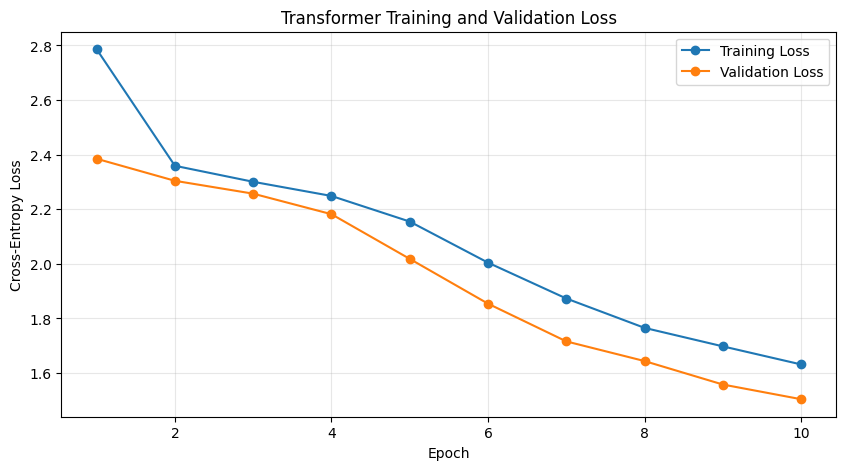

In [9]:
# ------------------------------------------------------------
# STEP 9: PLOT TRAINING AND VALIDATION LOSS
# ------------------------------------------------------------
plt.figure(figsize=(10, 5))
plt.plot(range(1, EPOCHS + 1), train_losses, marker="o", label="Training Loss")
plt.plot(range(1, EPOCHS + 1), validation_losses, marker="o", label="Validation Loss")
plt.title("Transformer Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [10]:
# ------------------------------------------------------------
# STEP 10: EVALUATE MODEL – VALIDATION LOSS AND PERPLEXITY
# ------------------------------------------------------------
final_metrics = estimate_loss(number_of_batches=50)
final_validation_loss = final_metrics["val"]
perplexity = math.exp(min(final_validation_loss, 20))

print("\\n" + "=" * 55)
print("MODEL EVALUATION")
print("=" * 55)
print("Training loss:", round(final_metrics["train"], 4))
print("Validation loss:", round(final_validation_loss, 4))
print("Perplexity:", round(perplexity, 4))

\n=======================================================
MODEL EVALUATION
Training loss: 1.5562
Validation loss: 1.5115
Perplexity: 4.5334


In [11]:
# ------------------------------------------------------------
# STEP 11: GENERATE STORIES
# ------------------------------------------------------------
def generate_story(prompt, max_new_tokens=400, temperature=0.8, top_k=40):
    unknown = sorted(set(ch for ch in prompt if ch not in stoi))
    if unknown:
        raise ValueError(f"Prompt contains characters outside vocabulary: {unknown}")
    input_ids = torch.tensor([encode(prompt)], dtype=torch.long, device=device)
    generated_ids = model.generate(
        input_ids,
        max_new_tokens=max_new_tokens,
        temperature=temperature,
        top_k=top_k
    )
    return decode(generated_ids[0].cpu().tolist())

main_prompt = "Once upon a time"
generated_story = generate_story(main_prompt, max_new_tokens=400)

print("\\nGENERATED STORY")
print("=" * 65)
print(generated_story)

test_prompts = [
    "One day, a little girl",
    "There was a small dog",
    "Once upon a time, a boy"
]
generated_examples = []
for prompt in test_prompts:
    result = generate_story(prompt, max_new_tokens=200)
    generated_examples.append({"prompt": prompt, "generated_text": result})
    print("\\nPROMPT:", prompt)
    print(result)

\nGENERATED STORY
Once upon a time.

The lry stay, Memmy. He famed And see was it that st the the poole. His mearstand thouse he was sune grom and smome, was a blare tally was it didd a boy saddy. He he said you go me. Bout was the his saw a liked to girlbe beaving fun. The bicy ranifelt were was a and saw so don the was day, buffeeture tured a and played and saw the was the care. They said, but at out he free. Joene boy the babba
\nPROMPT: One day, a little girl
One day, a little girl ave to blay that looked be could and said. 

Sam Sared and skippecided and her a smething "The it of the it him sor was da lottll Lily said, "No, Mom. He are waround them sach you with slide and said
\nPROMPT: There was a small dog
There was a small dog was good her and the learned the hime not boxt with scalle a bird. She see could and and to the culded and parted to ext they wanted the cope beele of the for himile was taoked the be seenamed it was
\nPROMPT: Once upon a time, a boy
Once upon a time, a b

In [12]:
# ------------------------------------------------------------
# STEP 12: EXPERIMENT WITH TRAINING EPOCHS
# Train a separate model for fewer epochs for comparison.
# ------------------------------------------------------------
EXPERIMENT_EPOCHS = 3
experiment_model = TinyTransformer().to(device)
experiment_optimizer = torch.optim.AdamW(
    experiment_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)
experiment_train_losses = []
experiment_val_losses = []

@torch.no_grad()
def evaluate_experiment(number_of_batches=VALIDATION_BATCHES):
    experiment_model.eval()
    losses = []
    for _ in range(number_of_batches):
        x, y = get_batch("val")
        _, loss = experiment_model(x, y)
        losses.append(loss.item())
    experiment_model.train()
    return float(np.mean(losses))

for epoch in range(EXPERIMENT_EPOCHS):
    experiment_model.train()
    epoch_losses = []
    for _ in range(STEPS_PER_EPOCH):
        x, y = get_batch("train")
        experiment_optimizer.zero_grad(set_to_none=True)
        logits, loss = experiment_model(x, y)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(experiment_model.parameters(), GRADIENT_CLIP)
        experiment_optimizer.step()
        epoch_losses.append(loss.item())

    train_loss = float(np.mean(epoch_losses))
    val_loss = evaluate_experiment()
    experiment_train_losses.append(train_loss)
    experiment_val_losses.append(val_loss)
    print(
        f"Experiment epoch {epoch + 1}/{EXPERIMENT_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | Validation Loss: {val_loss:.4f}"
    )


Experiment epoch 1/3 | Train Loss: 2.7810 | Validation Loss: 2.3860
Experiment epoch 2/3 | Train Loss: 2.3568 | Validation Loss: 2.2952
Experiment epoch 3/3 | Train Loss: 2.2985 | Validation Loss: 2.2360


,Experiment,Training Loss,Validation Loss
0,Main model (10 epochs),1.631503,1.504138
1,Experiment model (3 epochs),2.298458,2.236012


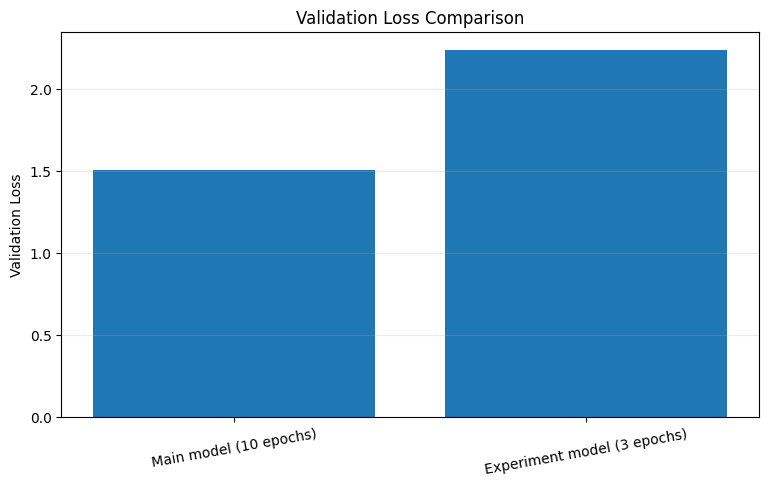

In [13]:
# ------------------------------------------------------------
# STEP 13: COMPARE EXPERIMENTAL RESULTS
# ------------------------------------------------------------
comparison = pd.DataFrame({
    "Experiment": [
        f"Main model ({EPOCHS} epochs)",
        f"Experiment model ({EXPERIMENT_EPOCHS} epochs)"
    ],
    "Training Loss": [train_losses[-1], experiment_train_losses[-1]],
    "Validation Loss": [validation_losses[-1], experiment_val_losses[-1]]
})
display(comparison)

plt.figure(figsize=(9, 5))
plt.bar(comparison["Experiment"], comparison["Validation Loss"])
plt.title("Validation Loss Comparison")
plt.ylabel("Validation Loss")
plt.xticks(rotation=10)
plt.grid(axis="y", alpha=0.25)
plt.show()



In [14]:
# ------------------------------------------------------------
# STEP 14: SAVE MODEL, VOCABULARY, CONFIGURATION AND RESULTS
# ------------------------------------------------------------
OUTPUT_DIR = r"D:\Labsheet\Lab-03-Tiny-Transformer\results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Save primary model weights
MODEL_PATH = os.path.join(OUTPUT_DIR, "tiny_transformer.pth")
torch.save(model.state_dict(), MODEL_PATH)

# Save vocabulary mapping; required to decode model token IDs later
with open(os.path.join(OUTPUT_DIR, "vocabulary.json"), "w", encoding="utf-8") as f:
    json.dump({"vocab": vocab}, f, ensure_ascii=False, indent=2)

# Save configuration and evaluation metrics
model_config = {
    "dataset": DATASET_NAME,
    "number_of_stories": len(stories),
    "tokenization": "character-level",
    "vocab_size": vocab_size,
    "embedding_size": EMBEDDING_SIZE,
    "num_heads": NUM_HEADS,
    "num_layers": NUM_LAYERS,
    "dropout": DROPOUT,
    "block_size": BLOCK_SIZE,
    "batch_size": BATCH_SIZE,
    "epochs": EPOCHS,
    "steps_per_epoch": STEPS_PER_EPOCH,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "gradient_clip": GRADIENT_CLIP,
    "final_validation_loss": final_validation_loss,
    "perplexity": perplexity,
    "device": str(device)
}
with open(os.path.join(OUTPUT_DIR, "model_config.json"), "w", encoding="utf-8") as f:
    json.dump(model_config, f, indent=4)

# Save training history and comparison table
history = pd.DataFrame({
    "Epoch": range(1, EPOCHS + 1),
    "Training Loss": train_losses,
    "Validation Loss": validation_losses
})
history.to_csv(os.path.join(OUTPUT_DIR, "training_history.csv"), index=False)
comparison.to_csv(os.path.join(OUTPUT_DIR, "experiment_comparison.csv"), index=False)

# Save generated stories
with open(os.path.join(OUTPUT_DIR, "generated_story.txt"), "w", encoding="utf-8") as f:
    f.write(generated_story)

with open(os.path.join(OUTPUT_DIR, "generated_prompt_examples.txt"), "w", encoding="utf-8") as f:
    for item in generated_examples:
        f.write("PROMPT: " + item["prompt"] + "\\n")
        f.write(item["generated_text"] + "\\n")
        f.write("\\n" + "=" * 65 + "\\n")

# Save training-loss figure
plt.figure(figsize=(10, 5))
plt.plot(range(1, EPOCHS + 1), train_losses, marker="o", label="Training Loss")
plt.plot(range(1, EPOCHS + 1), validation_losses, marker="o", label="Validation Loss")
plt.title("Transformer Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "training_loss.png"), dpi=150)
plt.close()

# Save comparison figure
plt.figure(figsize=(9, 5))
plt.bar(comparison["Experiment"], comparison["Validation Loss"])
plt.title("Validation Loss Comparison")
plt.ylabel("Validation Loss")
plt.xticks(rotation=10)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "experiment_comparison.png"), dpi=150)
plt.close()

print("\\n" + "=" * 65)
print("ALL OUTPUTS SAVED")
print("=" * 65)
for filename in sorted(os.listdir(OUTPUT_DIR)):
    path = os.path.join(OUTPUT_DIR, filename)
    print(f"{filename:38s} {os.path.getsize(path):>12,} bytes")
print("\\nSaved to:", OUTPUT_DIR)


\n=================================================================
ALL OUTPUTS SAVED
experiment_comparison.csv                       166 bytes
experiment_comparison.png                    43,050 bytes
generated_prompt_examples.txt                   975 bytes
generated_story.txt                             416 bytes
model_config.json                               502 bytes
tiny_transformer.pth                      2,277,621 bytes
training_history.csv                            431 bytes
training_loss.png                            74,959 bytes
vocabulary.json                                 735 bytes
\nSaved to: D:\Labsheet\Lab-03-Tiny-Transformer\results


In [15]:
# ------------------------------------------------------------
# STEP 15: PERFORMANCE MECHANISMS – DISCUSSION NOTES
# ------------------------------------------------------------
print("""
PERFORMANCE MECHANISMS USED
1. Causal masking prevents attention to future characters.
2. Multi-head attention learns different sequence relationships.
3. Positional embeddings provide token-position information.
4. Residual connections support information flow through layers.
5. Layer normalization helps stabilize model training.
6. Dropout can reduce overfitting.
7. AdamW provides adaptive optimization with weight decay.
8. Gradient clipping limits excessively large gradients.
9. Mini-batch training makes optimization computationally manageable.

Interpret the generated text and measured losses critically. A small model
trained on a limited subset may produce repetition or incomplete stories.
""")


PERFORMANCE MECHANISMS USED
1. Causal masking prevents attention to future characters.
2. Multi-head attention learns different sequence relationships.
3. Positional embeddings provide token-position information.
4. Residual connections support information flow through layers.
5. Layer normalization helps stabilize model training.
6. Dropout can reduce overfitting.
7. AdamW provides adaptive optimization with weight decay.
8. Gradient clipping limits excessively large gradients.
9. Mini-batch training makes optimization computationally manageable.

Interpret the generated text and measured losses critically. A small model
trained on a limited subset may produce repetition or incomplete stories.

